# Titanic Survival Prediction

End-to-end workflow: **load → analyse → EDA → feature engineering → modelling → prediction pipeline**.

Target: `Survived` (0 = did not survive, 1 = survived).

## 1. Imports

In [1]:
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "titanic.csv"
MODEL_DIR = PROJECT_ROOT / "models"
RANDOM_STATE = 42

## 2. Load dataset
Downloads the CSV into `data/` if it is not already there.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    resp = requests.get(DATA_URL, timeout=30)
    resp.raise_for_status()
    DATA_PATH.write_bytes(resp.content)

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")

Shape: 891 rows x 12 columns


## 3. Data overview

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


### Missing values per column

In [7]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2),
}).sort_values("missing", ascending=False)
missing[missing["missing"] > 0]

,missing,percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


In [8]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


**Observation:** 891 passengers, 12 columns, no duplicates. `Cabin` is 77% missing, `Age` 20% and `Embarked` only 2 rows. `Fare` is heavily skewed (median 14.45, max 512), and `Name`/`Ticket` are near-unique identifiers that need engineering before use.

## 4. Exploratory Data Analysis

### 4.1 Target distribution

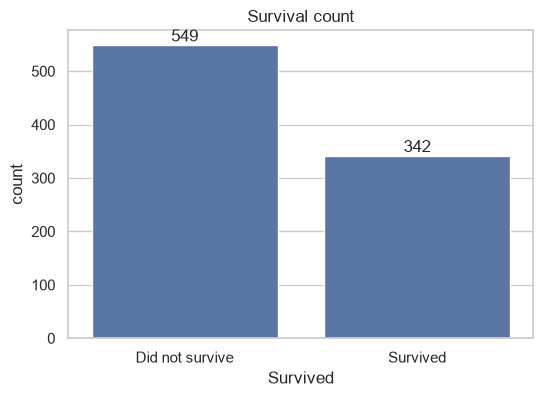

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Survived", ax=ax)
ax.set_xticks([0, 1], ["Did not survive", "Survived"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Survival count")
plt.show()
print(df["Survived"].value_counts(normalize=True).round(3))

**Observation:** The classes are moderately imbalanced: 61.6% did not survive and 38.4% survived. Accuracy is usable as a metric, but recall on survivors is worth watching.

### 4.2 Missing-value map

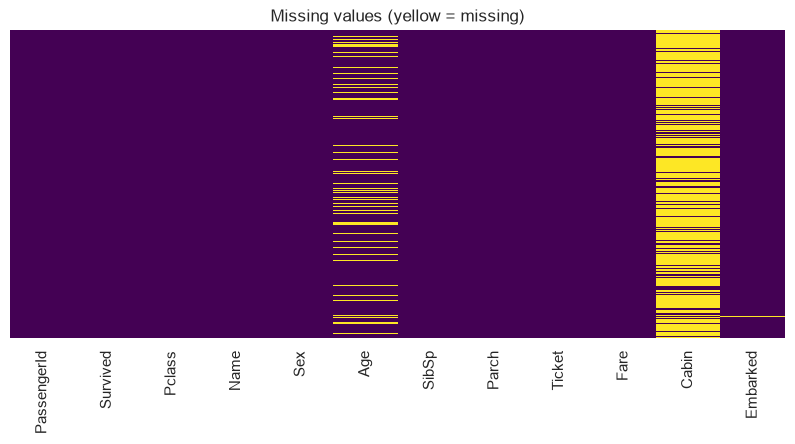

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis", ax=ax)
ax.set_title("Missing values (yellow = missing)")
plt.show()

**Observation:** Missing values are concentrated in `Cabin` (mostly empty) and `Age` (scattered). `Cabin` is better used as a has-cabin flag than imputed directly.

### 4.3 Survival by sex

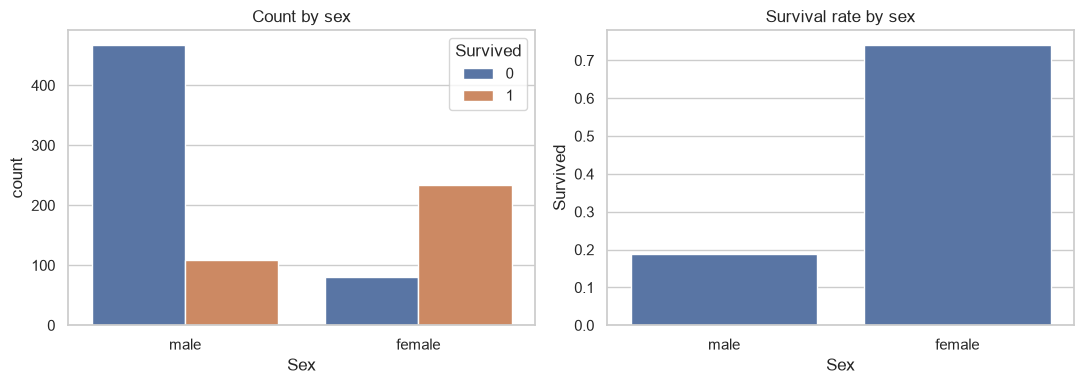

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="Sex", hue="Survived", ax=axes[0])
axes[0].set_title("Count by sex")
sns.barplot(data=df, x="Sex", y="Survived", ax=axes[1], errorbar=None)
axes[1].set_title("Survival rate by sex")
plt.tight_layout(); plt.show()
print(df.groupby("Sex")["Survived"].mean().round(3))

**Observation:** Sex is the strongest single signal: 74.2% of women survived versus 18.9% of men.

### 4.4 Survival by passenger class

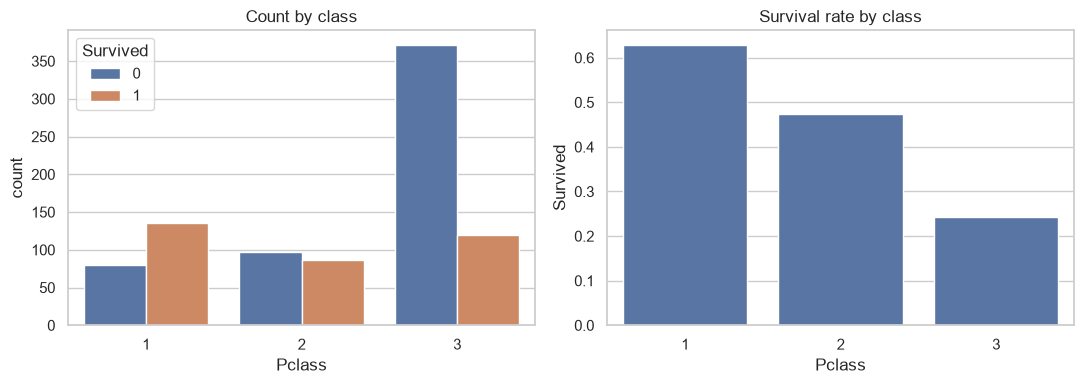

Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="Pclass", hue="Survived", ax=axes[0])
axes[0].set_title("Count by class")
sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1], errorbar=None)
axes[1].set_title("Survival rate by class")
plt.tight_layout(); plt.show()
print(df.groupby("Pclass")["Survived"].mean().round(3))

**Observation:** Survival falls steadily with class: 63.0% in 1st, 47.3% in 2nd and 24.2% in 3rd.

### 4.5 Class × sex interaction

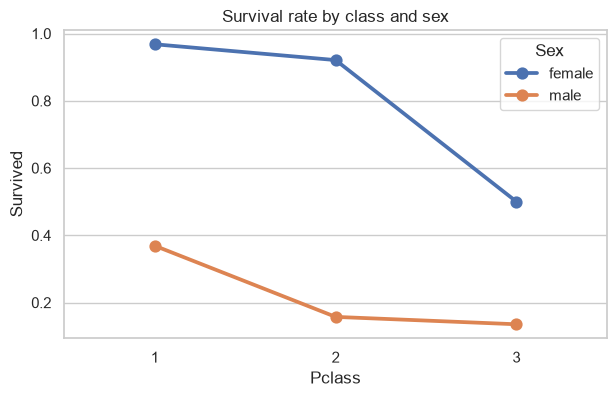

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.pointplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=None, ax=ax)
ax.set_title("Survival rate by class and sex")
plt.show()
df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean").round(3)

**Observation:** Women in 1st and 2nd class almost all survived (97%, 92%), but only 50% of 3rd-class women did. Men in 2nd and 3rd class fared worst (16%, 14%).

### 4.6 Age distribution

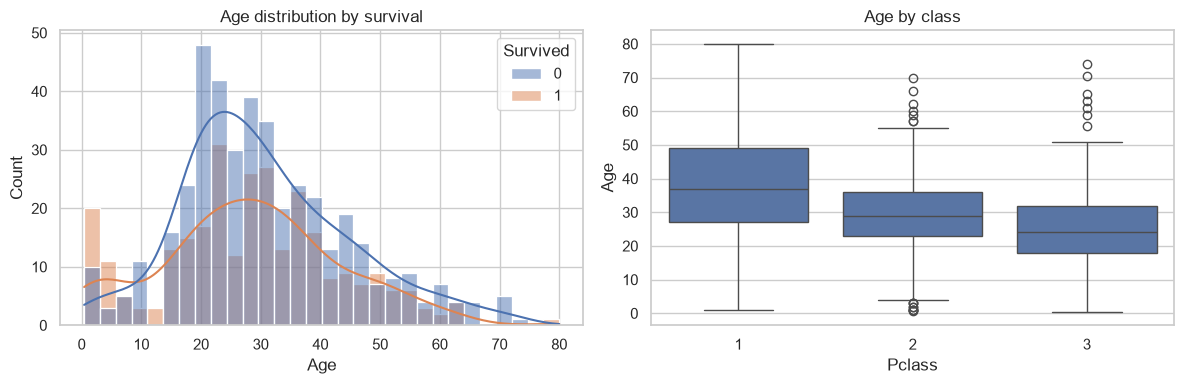

           mean  count
Age                   
(0, 12]   0.580     69
(12, 18]  0.429     70
(18, 30]  0.356    270
(30, 50]  0.423    241
(50, 80]  0.344     64


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age distribution by survival")
sns.boxplot(data=df, x="Pclass", y="Age", ax=axes[1])
axes[1].set_title("Age by class")
plt.tight_layout(); plt.show()
age_bins = pd.cut(df["Age"], [0, 12, 18, 30, 50, 80])
print(df.groupby(age_bins, observed=True)["Survived"].agg(["mean", "count"]).round(3))

**Observation:** Children aged 12 or under had the highest survival rate (58%). Adults' survival barely changes with age. Median age falls with class (37, 29, 24), so age partly overlaps with class.

### 4.7 Fare distribution

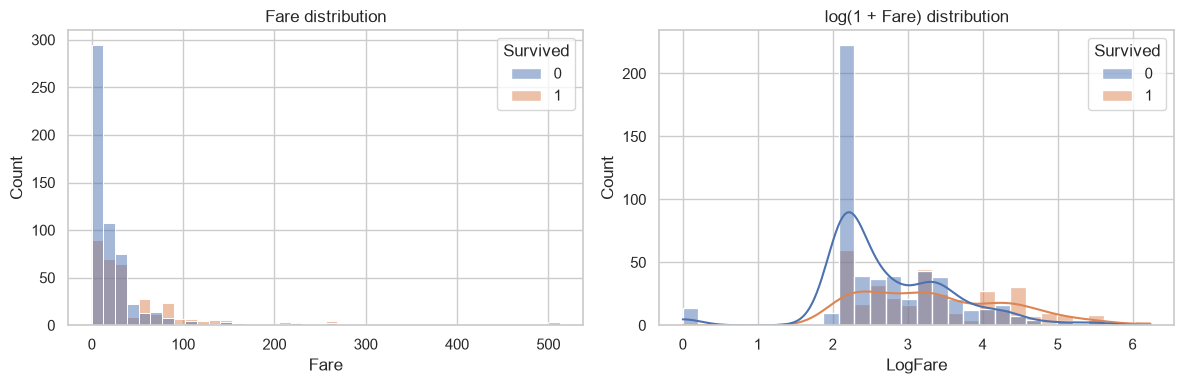

Survived
0    10.5
1    26.0
Name: Fare, dtype: float64


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="Fare", hue="Survived", bins=40, ax=axes[0])
axes[0].set_title("Fare distribution")
sns.histplot(data=df.assign(LogFare=np.log1p(df["Fare"])), x="LogFare", hue="Survived",
             bins=30, kde=True, ax=axes[1])
axes[1].set_title("log(1 + Fare) distribution")
plt.tight_layout(); plt.show()
print(df.groupby("Survived")["Fare"].median())

**Observation:** Survivors paid a much higher median fare (26.0 vs 10.5). The log transform shows survivors shifted toward higher fares, which mostly reflects class.

### 4.8 Port of embarkation

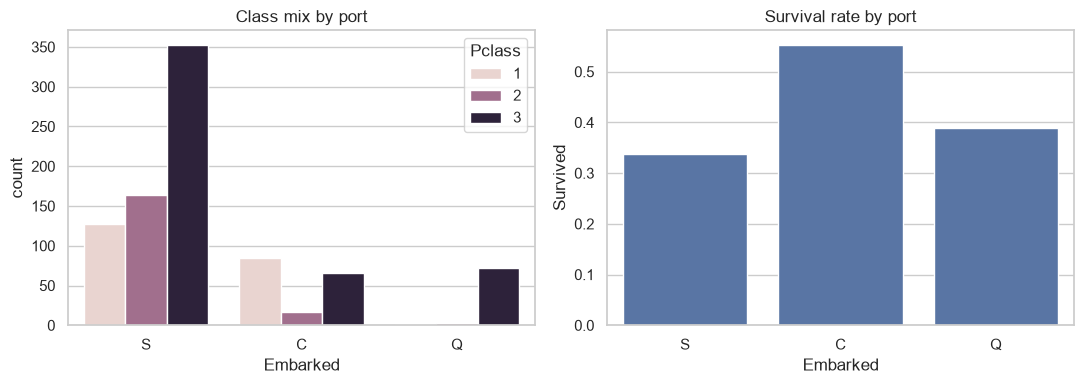

           mean  count
Embarked              
C         0.554    168
Q         0.390     77
S         0.337    644


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="Embarked", hue="Pclass", ax=axes[0])
axes[0].set_title("Class mix by port")
sns.barplot(data=df, x="Embarked", y="Survived", ax=axes[1], errorbar=None)
axes[1].set_title("Survival rate by port")
plt.tight_layout(); plt.show()
print(df.groupby("Embarked")["Survived"].agg(["mean", "count"]).round(3))

**Observation:** Passengers from Cherbourg (C) survived most (55%), but C also had a higher share of 1st-class passengers, so port is largely a proxy for class.

### 4.9 Siblings/spouses and parents/children aboard

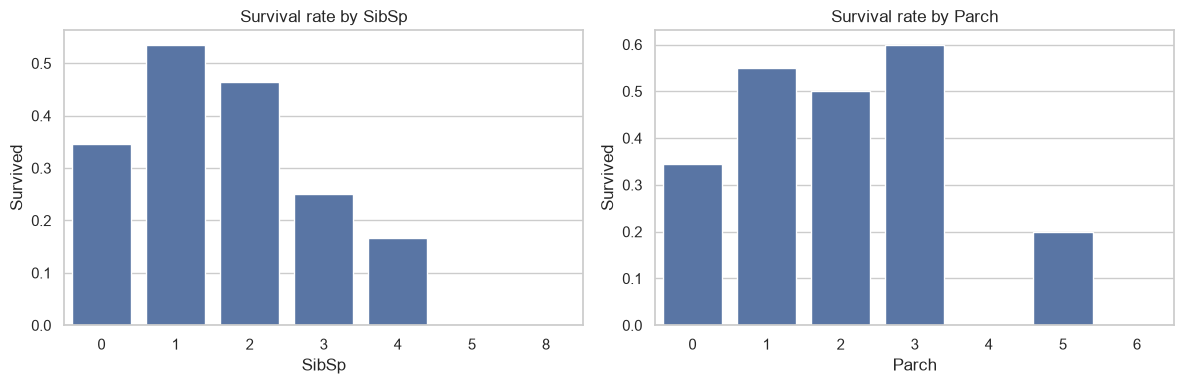

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x="SibSp", y="Survived", ax=axes[0], errorbar=None)
axes[0].set_title("Survival rate by SibSp")
sns.barplot(data=df, x="Parch", y="Survived", ax=axes[1], errorbar=None)
axes[1].set_title("Survival rate by Parch")
plt.tight_layout(); plt.show()

**Observation:** Passengers with 1–2 relatives aboard survived more often (~50–55%) than those travelling alone (~34%) or in large families (4+ siblings: ≤17%). The relationship is non-linear.

### 4.10 Correlation of numeric features

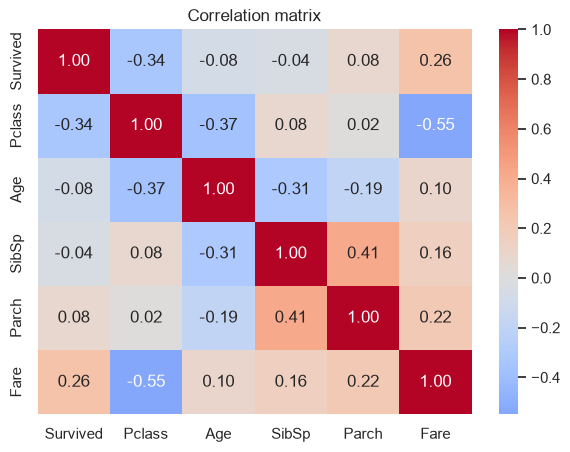

In [18]:
num = df.select_dtypes("number").drop(columns="PassengerId")
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

**Observation:** `Pclass` (−0.34) and `Fare` (+0.26) are the numeric features most correlated with survival, and they are strongly correlated with each other (−0.55). Age, SibSp and Parch are close to zero linearly, so their effect is non-linear.

## 5. Feature engineering

All engineering lives in one function, `add_features`, which becomes the first step of the model pipeline.
That means the same transformations are applied automatically at prediction time.

| Feature | How it's built | Why |
|---|---|---|
| `Title` | Extracted from `Name` (Mr, Mrs, Miss, Master, Rare) | Encodes sex, age group and social status |
| `FamilySize` | `SibSp + Parch + 1` | Combines both family columns |
| `IsAlone` | `FamilySize == 1` | Solo travellers behave differently |
| `HasCabin` | `Cabin` not missing | Proxy for wealth / class |
| `Deck` | First letter of `Cabin`, `U` if unknown | Location on the ship |
| `FarePerPerson` | `Fare / FamilySize` | Fare is per ticket, often shared |

Dropped: `PassengerId`, `Ticket` (identifiers), `Name` and `Cabin` (replaced by the features above).

In [19]:
TITLE_MAP = {
    "Mr": "Mr", "Master": "Master",
    "Miss": "Miss", "Mlle": "Miss", "Ms": "Miss",
    "Mrs": "Mrs", "Mme": "Mrs",
}
NUMERIC_FEATURES = ["Age", "Fare", "SibSp", "Parch", "FamilySize", "FarePerPerson"]
CATEGORICAL_FEATURES = ["Pclass", "Sex", "Embarked", "Title", "Deck", "IsAlone", "HasCabin"]


def extract_title(name: pd.Series) -> pd.Series:
    """'Braund, Mr. Owen Harris' -> 'Mr'; uncommon titles -> 'Rare'."""
    raw = name.astype(str).str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    return raw.map(TITLE_MAP).fillna("Rare")


def add_features(data: pd.DataFrame) -> pd.DataFrame:
    """Build model features from raw Titanic rows. Missing optional columns are tolerated."""
    data = data.copy()
    for col in ["Name", "Cabin", "SibSp", "Parch", "Fare", "Age", "Embarked"]:
        if col not in data:
            data[col] = np.nan

    data["Title"] = extract_title(data["Name"])
    data["FamilySize"] = data["SibSp"].fillna(0) + data["Parch"].fillna(0) + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
    data["HasCabin"] = data["Cabin"].notna().astype(int)
    data["Deck"] = data["Cabin"].astype("string").str[0].fillna("U").astype(object)
    data["FarePerPerson"] = data["Fare"] / data["FamilySize"]
    return data[NUMERIC_FEATURES + CATEGORICAL_FEATURES]

In [20]:
fe = add_features(df).assign(Survived=df["Survived"])
fe.head()

,Age,Fare,SibSp,Parch,FamilySize,FarePerPerson,Pclass,Sex,Embarked,Title,Deck,IsAlone,HasCabin,Survived
0,22.0,7.2500,1,0,2,3.62500,3,male,S,Mr,U,0,0,0
1,38.0,71.2833,1,0,2,35.64165,1,female,C,Mrs,C,0,1,1
2,26.0,7.9250,0,0,1,7.92500,3,female,S,Miss,U,1,0,1
3,35.0,53.1000,1,0,2,26.55000,1,female,S,Mrs,C,0,1,1
4,35.0,8.0500,0,0,1,8.05000,3,male,S,Mr,U,1,0,0


### 5.1 Survival by title

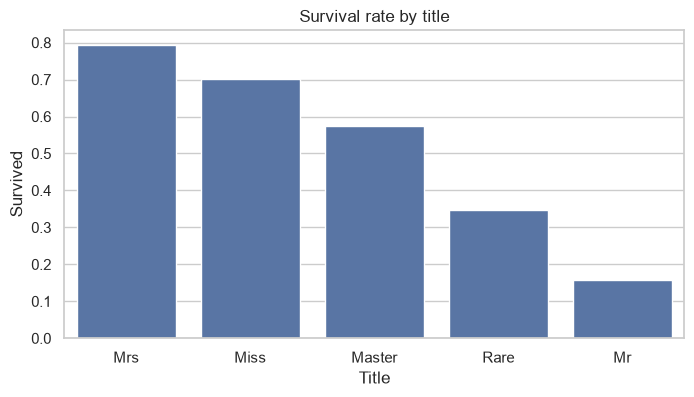

         mean  count
Title               
Master  0.575     40
Miss    0.703    185
Mr      0.157    517
Mrs     0.794    126
Rare    0.348     23


In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
order = fe.groupby("Title")["Survived"].mean().sort_values(ascending=False).index
sns.barplot(data=fe, x="Title", y="Survived", order=order, errorbar=None, ax=ax)
ax.set_title("Survival rate by title")
plt.show()
print(fe.groupby("Title")["Survived"].agg(["mean", "count"]).round(3))

**Observation:** Title separates the groups well: Mr 15.7% survival, Master (boys) 57.5%, Miss 70.3%, Mrs 79.4%. Title captures sex and age group in one feature.

### 5.2 Survival by family size

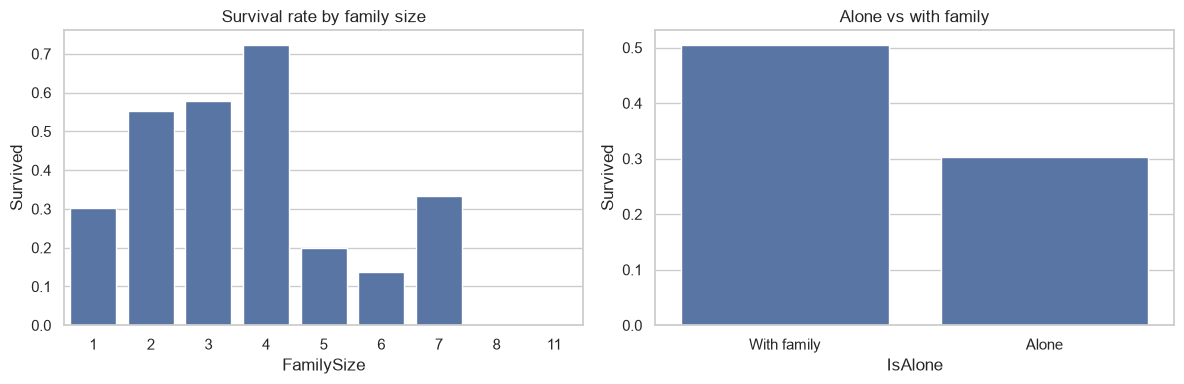

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=fe, x="FamilySize", y="Survived", errorbar=None, ax=axes[0])
axes[0].set_title("Survival rate by family size")
sns.barplot(data=fe, x="IsAlone", y="Survived", errorbar=None, ax=axes[1])
axes[1].set_xticks([0, 1], ["With family", "Alone"])
axes[1].set_title("Alone vs with family")
plt.tight_layout(); plt.show()

**Observation:** Families of 2–4 had the best survival (55–72%). Solo travellers (30%) and families of 5 or more (≤20%) did much worse.

### 5.3 Survival by cabin deck

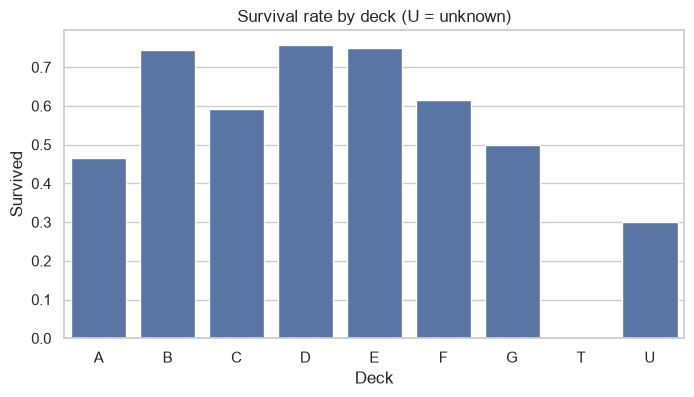

           mean  count
HasCabin              
0         0.300    687
1         0.667    204


In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=fe, x="Deck", y="Survived", order=sorted(fe["Deck"].unique()), errorbar=None, ax=ax)
ax.set_title("Survival rate by deck (U = unknown)")
plt.show()
print(fe.groupby("HasCabin")["Survived"].agg(["mean", "count"]).round(3))

**Observation:** Passengers with a recorded cabin survived at 66.7% versus 30.0% without one. Decks B, D and E were the highest (~75%), but each has few passengers.

## 6. Model development

### 6.1 Train / test split
Stratified 80/20 split so both sets keep the same survival ratio.

In [24]:
X = df.drop(columns="Survived")
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (712, 11) Test: (179, 11)


### 6.2 Preprocessing pipeline
Raw rows → `add_features` → numeric: median impute + scale; categorical: most-frequent impute + one-hot.
Everything is fitted on training data only, so there is no leakage into the test set.

In [25]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC_FEATURES),
    ("cat", categorical_pipe, CATEGORICAL_FEATURES),
])

def make_pipeline(model):
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("preprocess", preprocessor),
        ("model", model),
    ])

### 6.3 Compare baseline models (5-fold cross-validation)

In [26]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in candidates.items():
    scores = cross_val_score(make_pipeline(model), X_train, y_train, cv=cv, scoring="accuracy")
    rows.append({"model": name, "cv_mean": scores.mean(), "cv_std": scores.std()})
cv_results = pd.DataFrame(rows).sort_values("cv_mean", ascending=False).reset_index(drop=True)
cv_results.round(4)

,model,cv_mean,cv_std
0,Logistic Regression,0.8259,0.0235
1,Gradient Boosting,0.8259,0.0229
2,Random Forest,0.8188,0.0117


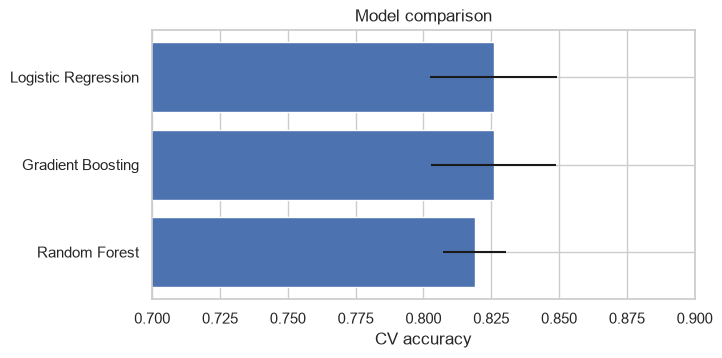

In [27]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(cv_results["model"], cv_results["cv_mean"], xerr=cv_results["cv_std"])
ax.set_xlim(0.7, 0.9)
ax.invert_yaxis()
ax.set_xlabel("CV accuracy")
ax.set_title("Model comparison")
plt.show()

**Observation:** All three models score close to each other (~82–83% CV accuracy). Logistic Regression and Gradient Boosting tie at 82.6%, and Random Forest is slightly lower but with the least variance.

### 6.4 Hyperparameter tuning (best two model families)

In [28]:
search_spaces = {
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [200, 400],
            "model__max_depth": [4, 6, 8, None],
            "model__min_samples_leaf": [1, 2, 4],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.05, 0.1],
            "model__max_depth": [2, 3, 4],
        },
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=1000),
        {"model__C": [0.01, 0.1, 1, 10]},
    ),
}

searches = {}
for name in cv_results["model"].head(2):
    model, grid = search_spaces[name]
    gs = GridSearchCV(make_pipeline(model), grid, cv=cv, scoring="accuracy", n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name}: best CV accuracy {gs.best_score_:.4f} with {gs.best_params_}")

best_name = max(searches, key=lambda n: searches[n].best_score_)
best_pipeline = searches[best_name].best_estimator_
print("\nSelected model:", best_name)

Logistic Regression: best CV accuracy 0.8259 with {'model__C': 1}


Gradient Boosting: best CV accuracy 0.8315 with {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 200}

Selected model: Gradient Boosting


### 6.5 Evaluate on the held-out test set

In [29]:
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Test ROC AUC:  {roc_auc_score(y_test, y_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"]))

Test accuracy: 0.8045
Test ROC AUC:  0.8344

                 precision    recall  f1-score   support

Did not survive       0.82      0.88      0.85       110
       Survived       0.78      0.68      0.73        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



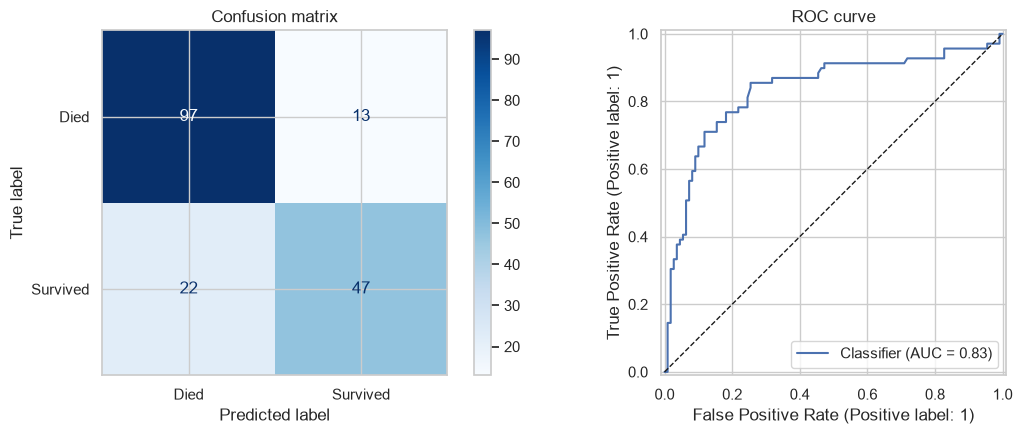

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Died", "Survived"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

**Observation:** On the 179-passenger test set, the tuned Gradient Boosting model gets 80.4% accuracy and 0.83 ROC AUC. It predicts deaths well (recall 0.88) but misses about a third of survivors (recall 0.68).

### 6.6 Feature importance

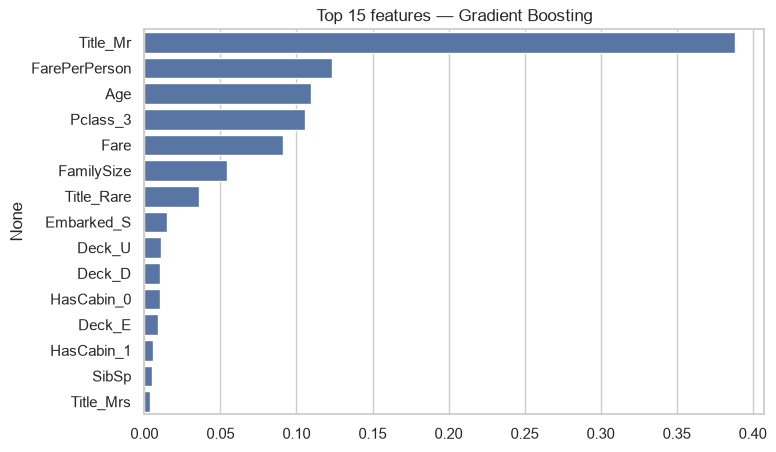

In [31]:
model = best_pipeline.named_steps["model"]
feature_names = best_pipeline.named_steps["preprocess"].get_feature_names_out()
weights = model.feature_importances_ if hasattr(model, "feature_importances_") else np.abs(model.coef_[0])
importance = (pd.Series(weights, index=[f.split("__", 1)[1] for f in feature_names])
                .sort_values(ascending=False).head(15))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, ax=ax)
ax.set_title(f"Top 15 features — {best_name}")
plt.show()

**Observation:** `Title_Mr` dominates the model's decisions, followed by fare (per person and total), age and 3rd-class membership. This matches the EDA: sex/title and class drive survival.

### 6.7 Final fit and save
Refit the chosen pipeline on **all** labelled data, then save it. The saved file contains feature engineering,
preprocessing and the model, so it takes raw passenger rows as input.

In [32]:
final_pipeline = best_pipeline.fit(X, y)
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "titanic_pipeline.joblib"
joblib.dump(final_pipeline, MODEL_PATH)
print("Saved to", MODEL_PATH)

Saved to C:\Users\anant\Desktop\New folder\models\titanic_pipeline.joblib


## 7. Prediction pipeline
Load the saved pipeline and predict for new passengers. Only raw columns are needed; any missing
optional fields (e.g. `Cabin`, `Age`) are imputed.

> The saved pipeline references `add_features`, so to load it outside this notebook, that function
> (and `extract_title`, `TITLE_MAP`) must be defined in the loading script's `__main__` first.

In [33]:
def predict_survival(passengers, model_path=MODEL_PATH):
    """Predict survival for one passenger (dict) or many (list of dicts / DataFrame)."""
    pipeline = joblib.load(model_path)
    if isinstance(passengers, dict):
        passengers = [passengers]
    X_new = pd.DataFrame(passengers)
    proba = pipeline.predict_proba(X_new)[:, 1]
    return X_new.assign(
        survival_probability=proba.round(3),
        prediction=np.where(proba >= 0.5, "Survived", "Did not survive"),
    )

new_passengers = [
    {"Pclass": 1, "Name": "Doe, Mrs. Jane", "Sex": "female", "Age": 35, "SibSp": 1, "Parch": 0,
     "Ticket": "PC 1234", "Fare": 80.0, "Cabin": "C85", "Embarked": "C"},
    {"Pclass": 3, "Name": "Smith, Mr. John", "Sex": "male", "Age": 28, "SibSp": 0, "Parch": 0,
     "Ticket": "A/5 999", "Fare": 7.25, "Cabin": None, "Embarked": "S"},
    {"Pclass": 2, "Name": "Brown, Master. Tom", "Sex": "male", "Age": 6, "SibSp": 1, "Parch": 2,
     "Ticket": "2468", "Fare": 30.0, "Embarked": "S"},  # no Cabin key at all
]
predict_survival(new_passengers)[["Name", "Pclass", "Sex", "Age", "survival_probability", "prediction"]]

,Name,Pclass,Sex,Age,survival_probability,prediction
0,"Doe, Mrs. Jane",1,female,35,0.976,Survived
1,"Smith, Mr. John",3,male,28,0.065,Did not survive
2,"Brown, Master. Tom",2,male,6,0.956,Survived


## 8. Summary

- **Data**: 891 passengers. `Cabin` (77%) and `Age` (20%) are the main gaps; both are handled inside the pipeline (has-cabin flag/deck, median imputation).
- **Key drivers**: sex/title, passenger class and fare, then age (children favoured) and family size (small families favoured).
- **Engineered features**: `Title`, `FamilySize`, `IsAlone`, `HasCabin`, `Deck`, `FarePerPerson`. `Title` turned out to be the most important feature in the model.
- **Model**: tuned Gradient Boosting (`learning_rate=0.05`, `max_depth=4`, `n_estimators=200`): 83.2% CV accuracy, 80.4% test accuracy, 0.83 ROC AUC.
- **Weak spot**: recall for survivors is 0.68. Lowering the 0.5 decision threshold would trade some precision for catching more survivors.
- **Output**: `models/titanic_pipeline.joblib` is a single pipeline that takes raw passenger rows; use `predict_survival()` for new predictions.